# Задание 6. Работа с текстовыми данными (классификация текстов)

Датасет `ESG.csv`: 447 фрагментов из нефинансовых отчётов российских компаний (МТС, НЛМК, ФосАгро, Магнит и др.). Каждый фрагмент эксперт отнёс к одной из 45 тем ESG-анализа.

- `true_expert` – тема фрагмента по разметке эксперта;
- `original_text` – текст фрагмента.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
from pymystem3 import Mystem

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

RS = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

In [2]:
df = pd.read_csv("ESG.csv", sep=";")
print(df.shape, "пропусков:", df.isna().sum().sum(), " дубликатов текста:", df["original_text"].duplicated().sum())
print("тем:", df["true_expert"].nunique())
print("длина текста, символов:"); print(df["original_text"].str.len().describe().round(0))
df.head()

(447, 2) пропусков: 0  дубликатов текста: 0
тем: 45
длина текста, символов:
count     447.0
mean      418.0
std       284.0
min        80.0
25%       242.0
50%       359.0
75%       488.0
max      3223.0
Name: original_text, dtype: float64


,true_expert,original_text
0,Отходы,"Основную массу отходов Группы составляют отходы, образующиеся в результате деятельности по производству бортового пи..."
1,Удовлетворенность потребителей,"изучение обратной связи от покупателей позволит магниту повысить преимущества своих брендов и запускать позиции, соо..."
2,Оплата труда,Материальное вознаграждение сотрудников состоит из базовой части заработной платы и премиальной. Система оплаты труд...
3,Отчетность и прозрачность,"При наличии каких-либо допущений в сборе или подсчете данных, а также при корректировке значений предыдущих отчетных..."
4,Доступность продуктов,отдельное внимание банк уделяет повышению доступности своих точек обслуживания для лиц с ограниченными возможностями...


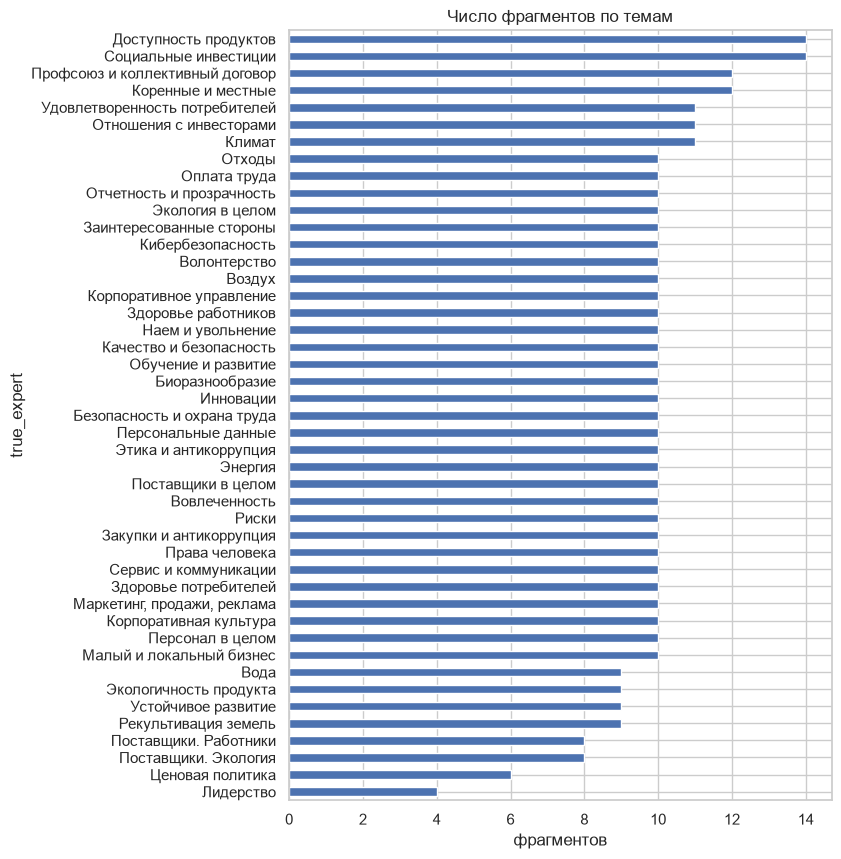

In [3]:
df["true_expert"].value_counts().plot.barh(figsize=(7, 10), color="#4C72B0")
plt.gca().invert_yaxis(); plt.title("Число фрагментов по темам"); plt.xlabel("фрагментов")
plt.show()

## Выбор целевого класса

Тем 45, на каждую приходится от 4 до 14 фрагментов. Если взять одну тему как положительный класс, в тест 20% попадёт два текста, и F1 будет прыгать между 0, 0.5 и 1 от одной ошибки. Поэтому объединяю темы в три блока ESG – E (экология), S (социальное), G (управление) – и решаю бинарную задачу: **относится ли фрагмент к экологическому блоку E** (`y = 1`) или нет (`y = 0`).

В блок E отношу 10 тем: отходы, климат, экология в целом, воздух, биоразнообразие, энергия, вода, экологичность продукта, рекультивация земель, «Поставщики. Экология».

In [4]:
E_topics = ["Отходы", "Климат", "Экология в целом", "Воздух", "Биоразнообразие", "Энергия", "Вода",
            "Экологичность продукта", "Рекультивация земель", "Поставщики. Экология"]
G_topics = ["Корпоративное управление", "Отчетность и прозрачность", "Отношения с инвесторами", "Риски",
            "Этика и антикоррупция", "Закупки и антикоррупция", "Кибербезопасность", "Персональные данные",
            "Заинтересованные стороны", "Устойчивое развитие", "Лидерство", "Инновации"]
df["pillar"] = np.where(df["true_expert"].isin(E_topics), "E",
                        np.where(df["true_expert"].isin(G_topics), "G", "S"))
df["y"] = (df["pillar"] == "E").astype(int)
y = df["y"].values

print(df["pillar"].value_counts())
print("доля класса E:", round(y.mean(), 3))

pillar
S    237
G    114
E     96
Name: count, dtype: int64
доля класса E: 0.215


Класс E занимает 21% выборки. Модель, которая всегда отвечает «не экология», получит Accuracy 0.785 и не найдёт ни одного экологического текста. Поэтому главными считаю F1, Precision и Recall, Accuracy смотрю вместе с ними.

## 1.1. Токенизация и предобработка, стемминг

Шаги для каждого текста:

1. привожу к нижнему регистру и заменяю «ё» на «е»;
2. удаляю всё, кроме русских и латинских букв: знаки препинания, спецсимволы (`•`, `«»`, `>`), цифры. Цифр в отчётах много (годы, тонны, проценты), но сами по себе они тему не определяют;
3. разбиваю текст на токены по пробелам;
4. удаляю стоп-слова из списка nltk и однобуквенные токены. К списку nltk добавляю слова, которые встречаются в отчётах любой тематики: «компания», «группа», «год», «также», «это»;
5. стемминг: Snowball-стеммер для русского языка отрезает окончания и суффиксы. После него ещё раз убираю стоп-слова, уже по основам: в списке nltk стоит «который», а в тексте встречаются «которые», «которых», и до стемминга они фильтр проходят.

In [5]:
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("russian"))
stop_words.update(["это", "весь", "который", "свой", "также", "компания", "группа", "год", "пао", "оао"])

stemmer = SnowballStemmer("russian")

def tokenize(text):
    text = str(text).lower().replace("ё", "е")
    text = re.sub(r"[^а-яa-z\s]", " ", text)
    return [t for t in text.split() if len(t) > 1 and t not in stop_words]

# список стоп-слов содержит начальные формы: «группа» удалится, а «группы» нет.
# Поэтому после стемминга удаляю ещё и основы стоп-слов
stop_stems = {stemmer.stem(w) for w in stop_words}

def preprocess_stem(text):
    stems = (stemmer.stem(t) for t in tokenize(text))
    return " ".join(s for s in stems if len(s) > 1 and s not in stop_stems)

df["clean_stem"] = df["original_text"].apply(preprocess_stem)

i = 0
print("Исходный текст:\n", df.loc[i, "original_text"][:400], "\n")
print("Токены:\n", tokenize(df.loc[i, "original_text"])[:30], "\n")
print("После стемминга:\n", df.loc[i, "clean_stem"][:400])

Исходный текст:
 Основную массу отходов Группы составляют отходы, образующиеся в результате деятельности по производству бортового питания и уборки салонов воздушных судов, а также прочие отходы, образующиеся в результате деятельности по техническому обслуживанию авиационной техники (масла, смазки, химические материалы, металлические и неметаллические конструктивные элементы, покрышки и другие запчасти) и работы о 

Токены:
 ['основную', 'массу', 'отходов', 'группы', 'составляют', 'отходы', 'образующиеся', 'результате', 'деятельности', 'производству', 'бортового', 'питания', 'уборки', 'салонов', 'воздушных', 'судов', 'прочие', 'отходы', 'образующиеся', 'результате', 'деятельности', 'техническому', 'обслуживанию', 'авиационной', 'техники', 'масла', 'смазки', 'химические', 'материалы', 'металлические'] 

После стемминга:
 основн масс отход составля отход образ результат деятельн производств бортов питан уборк салон воздушн суд проч отход образ результат деятельн техническ обслуживан авиа

In [6]:
n_raw = df["original_text"].str.split().str.len()
n_clean = df["clean_stem"].str.split().str.len()
print(f"слов в тексте до обработки: {n_raw.mean():.0f}, после: {n_clean.mean():.0f} (в среднем)")

слов в тексте до обработки: 51, после: 36 (в среднем)


## 1.2. Мешок слов и разбиение 80/20

Делю выборку на обучающую и тестовую в соотношении 80/20 со стратификацией по `y`, чтобы доля экологических текстов в обеих частях была одинаковой.

Словарь мешка слов строю **только по обучающей выборке**. Слова, которые встречаются только в тесте, модель не видела при обучении, и `CountVectorizer` их отбрасывает.

In [7]:
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=RS)
y_tr, y_te = y[idx_tr], y[idx_te]
print("обучение:", len(idx_tr), "текстов, из них E:", y_tr.sum())
print("тест:    ", len(idx_te), "текстов, из них E:", y_te.sum())

bow = CountVectorizer()
X_tr_bow = bow.fit_transform(df.loc[idx_tr, "clean_stem"])
X_te_bow = bow.transform(df.loc[idx_te, "clean_stem"])
print("\nразмер словаря:", len(bow.vocabulary_))
print("матрица train:", X_tr_bow.shape, " доля ненулевых:", round(X_tr_bow.nnz / np.prod(X_tr_bow.shape), 4))

обучение: 357 текстов, из них E: 77
тест:     90 текстов, из них E: 19

размер словаря: 2920
матрица train: (357, 2920)  доля ненулевых: 0.0102


In [8]:
# фрагмент матрицы «текст × токен»: первые 5 текстов и самые частые токены
freq = np.asarray(X_tr_bow.sum(axis=0)).ravel()
top = freq.argsort()[::-1][:12]
pd.DataFrame(X_tr_bow[:5, top].toarray(), columns=bow.get_feature_names_out()[top],
             index=[f"текст {k}" for k in idx_tr[:5]]).assign(y=y_tr[:5])

,сотрудник,работ,развит,управлен,риск,проект,деятельн,систем,соответств,област,корпоративн,программ,y
текст 282,0,2,0,0,0,0,0,0,0,0,1,1,0
текст 208,0,0,0,0,0,2,0,0,0,0,0,0,0
текст 376,0,0,0,0,0,0,0,1,1,0,0,0,0
текст 60,0,0,0,0,0,0,0,0,0,0,0,0,0
текст 280,0,1,0,0,0,0,0,0,0,0,0,0,0


In [9]:
# какие основы чаще встречаются в каждом классе
vocab = bow.get_feature_names_out()
for cls, name in [(1, "E"), (0, "не E")]:
    f = np.asarray(X_tr_bow[y_tr == cls].sum(axis=0)).ravel()
    print(f"{name:5s}:", ", ".join(vocab[f.argsort()[::-1][:20]]))

E    : экологическ, работ, земел, соответств, требован, област, выброс, газ, отход, проект, сред, систем, поставщик, изменен, реализац, риск, состав, программ, деятельн, рекультивац
не E : сотрудник, развит, управлен, работ, риск, корпоративн, проект, безопасн, деятельн, систем, прав, работник, дан, соответств, программ, труд, област, оценк, цел, процесс


В словаре 2920 основ, а один текст использует в среднем 1% из них (доля ненулевых ячеек 0.0102), матрица почти целиком из нулей. Самые частые основы общие для обоих классов: «работ», «проект», «систем», «риск». Классы различают другие слова: у экологических текстов «экологическ», «выброс», «газ», «отход», «земел», «рекультивац», у остальных «сотрудник», «развит», «управлен», «корпоративн», «труд».

## 1.3. Три модели и повышение их качества

Беру три модели из прошлых заданий, которые подходят для разреженных признаков:

- **логистическая регрессия** – линейная модель, вес каждого слова виден в коэффициентах;
- **мультиномиальный наивный Байес** – классика для мешка слов, оценивает частоту каждого слова внутри класса;
- **линейный SVM** – ищет разделяющую гиперплоскость с максимальным зазором. У `LinearSVC` нет вероятностей, поэтому оборачиваю его в `CalibratedClassifierCV`, иначе не построить ROC-кривую.

Сначала обучаю модели с параметрами по умолчанию. Затем применяю методы повышения качества:

1. **подбор гиперпараметров** `GridSearchCV` на 5-fold стратифицированной кросс-валидации внутри обучающей выборки по F1: сила регуляризации `C` для LogReg и SVM, сглаживание `alpha` для Naive Bayes;
2. **взвешивание классов** `class_weight="balanced"`: ошибка на редком классе E стоит дороже, чем на частом;
3. **настройка мешка слов**: биграммы (`ngram_range=(1, 2)`) и отсечение редких слов (`min_df=2`) тоже входят в сетку.

`CountVectorizer` стоит внутри `Pipeline`, поэтому на каждом фолде словарь строится заново только по обучающей части фолда.

In [10]:
def scores(y_true, pred, proba):
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, proba)}

def make_pipe(clf):
    return Pipeline([("bow", CountVectorizer()), ("clf", clf)])

models = {
    "LogReg": (LogisticRegression(max_iter=5000),
               {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Naive Bayes": (MultinomialNB(),
                    {"clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
    "SVM": (CalibratedClassifierCV(LinearSVC(), cv=5),
            {"clf__estimator__C": [0.001, 0.01, 0.1, 1], "clf__estimator__class_weight": [None, "balanced"]}),
}
bow_grid = {"bow__ngram_range": [(1, 1), (1, 2)], "bow__min_df": [1, 2]}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def run_all(col, tag):
    """Обучает три модели с параметрами по умолчанию и после GridSearchCV на тексте из столбца col."""
    X_tr, X_te = df.loc[idx_tr, col].values, df.loc[idx_te, col].values
    res, out, best = {}, {}, {}
    for name, (clf, grid) in models.items():
        base = make_pipe(clone(clf)).fit(X_tr, y_tr)
        proba = base.predict_proba(X_te)[:, 1]
        res[f"{name} ({tag}, базовая)"] = scores(y_te, base.predict(X_te), proba)
        out[f"{name} ({tag}, базовая)"] = (base.predict(X_te), proba)

        gs = GridSearchCV(make_pipe(clone(clf)), {**grid, **bow_grid}, scoring="f1", cv=skf, n_jobs=-1).fit(X_tr, y_tr)
        proba = gs.predict_proba(X_te)[:, 1]
        res[f"{name} ({tag})"] = {**scores(y_te, gs.predict(X_te), proba), "F1 CV (train)": gs.best_score_}
        out[f"{name} ({tag})"] = (gs.predict(X_te), proba)
        best[name] = gs.best_estimator_
        print(f"{name:12s} лучшие параметры: {gs.best_params_}")
    return pd.DataFrame(res).T, out, best

res_stem, out_stem, best_stem = run_all("clean_stem", "стемминг")

LogReg       лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__C': 0.1, 'clf__class_weight': 'balanced'}


Naive Bayes  лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__alpha': 0.5}


SVM          лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__estimator__C': 0.01, 'clf__estimator__class_weight': None}


## 1.4. Сравнение моделей

In [11]:
res_stem.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,F1 CV (train)
"LogReg (стемминг, базовая)",0.900,0.857,0.632,0.727,0.981,NaN
LogReg (стемминг),0.933,0.882,0.789,0.833,0.986,0.775
"Naive Bayes (стемминг, базовая)",0.989,1.000,0.947,0.973,0.996,NaN
Naive Bayes (стемминг),0.989,1.000,0.947,0.973,0.994,0.852
"SVM (стемминг, базовая)",0.922,0.875,0.737,0.800,0.971,NaN
SVM (стемминг),0.911,0.867,0.684,0.765,0.986,0.768


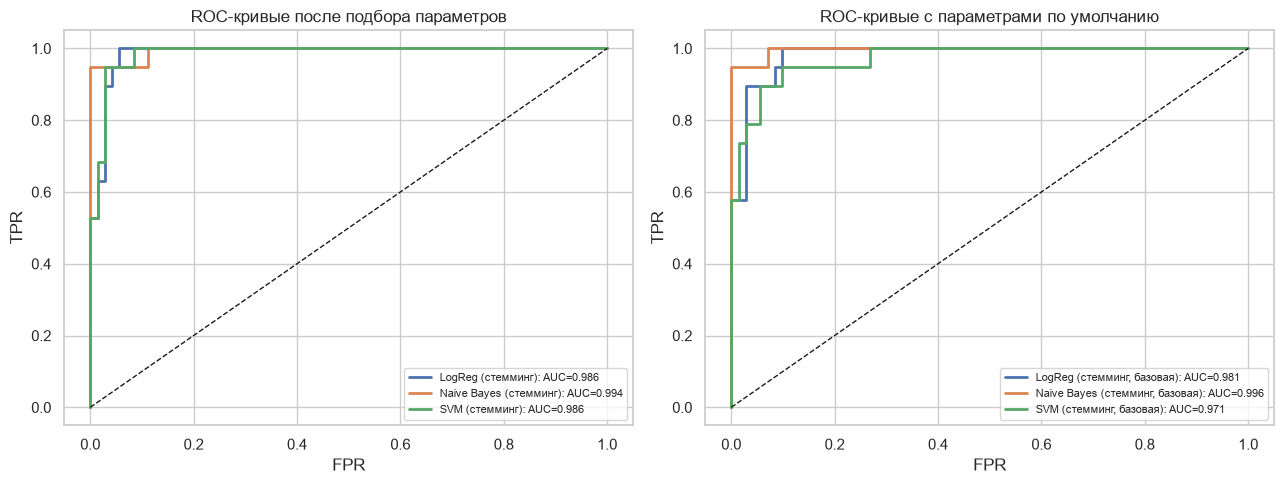

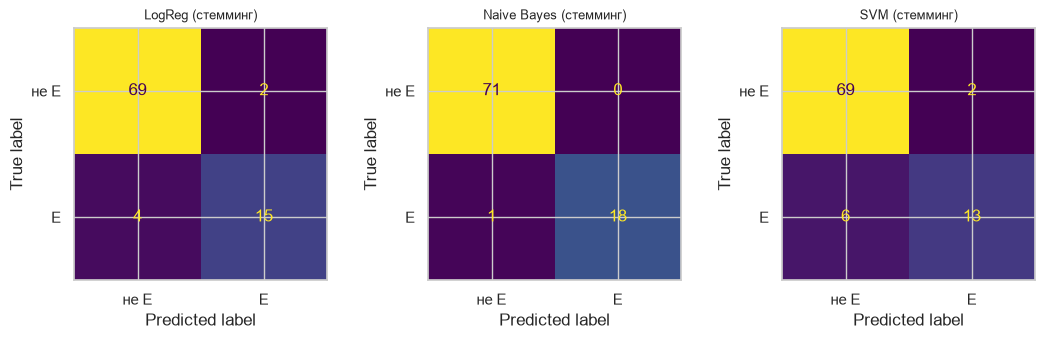

In [12]:
def plot_roc(out, keys, title, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for k in keys:
        fpr, tpr, _ = roc_curve(y_te, out[k][1])
        ax.plot(fpr, tpr, lw=2, label=f"{k}: AUC={roc_auc_score(y_te, out[k][1]):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_title(title); ax.legend(fontsize=8, loc="lower right")

def plot_cm(out, keys):
    fig, axes = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 3.4))
    for ax, k in zip(np.atleast_1d(axes), keys):
        ConfusionMatrixDisplay(confusion_matrix(y_te, out[k][0]), display_labels=["не E", "E"]).plot(ax=ax, colorbar=False)
        ax.set_title(k, fontsize=9)
    plt.tight_layout(); plt.show()

tuned_stem = [k for k in out_stem if "базовая" not in k]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
plot_roc(out_stem, tuned_stem, "ROC-кривые после подбора параметров", ax[0])
plot_roc(out_stem, [k for k in out_stem if "базовая" in k], "ROC-кривые с параметрами по умолчанию", ax[1])
plt.tight_layout(); plt.show()
plot_cm(out_stem, tuned_stem)

В тесте всего 19 экологических текстов, и одна ошибка сдвигает Recall на 0.05. Чтобы проверить, не повезло ли с разбиением, оцениваю подобранные модели ещё и повторной кросс-валидацией на всей выборке: 5 фолдов × 3 повтора, 15 оценок F1 на каждую модель.

In [13]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)

def cv_f1(best, col, tag):
    rows = {}
    for name, pipe in best.items():
        s = cross_val_score(clone(pipe), df[col].values, y, scoring="f1", cv=rskf, n_jobs=-1)
        rows[f"{name} ({tag})"] = {"F1 CV mean": s.mean(), "F1 CV std": s.std(), "F1 CV min": s.min()}
    return pd.DataFrame(rows).T

cv_stem = cv_f1(best_stem, "clean_stem", "стемминг")
cv_stem.round(3)

,F1 CV mean,F1 CV std,F1 CV min
LogReg (стемминг),0.803,0.067,0.667
Naive Bayes (стемминг),0.884,0.044,0.842
SVM (стемминг),0.800,0.061,0.710


#### Выводы по 1.4

На тесте лучший наивный Байес: F1 0.973, Precision 1.000, Recall 0.947. Он нашёл 18 экологических текстов из 19 и не дал ни одной ложной тревоги. Логистическая регрессия после подбора нашла 15 из 19 при двух ложных тревогах (F1 0.833), SVM – 13 из 19 (F1 0.765).

Подбор параметров сильнее всего помог логистической регрессии: F1 вырос с 0.727 до 0.833, Recall с 0.632 до 0.789. Сетка выбрала `class_weight="balanced"`, и модель перестала жертвовать редким классом. Наивному Байесу подбор ничего не добавил: F1 остался 0.973. У SVM F1 на тесте даже упал, с 0.800 до 0.765. GridSearch выбирал параметры по кросс-валидации на обучающей части, а разница 0.035 на тесте означает один текст из 19. Биграммы и `min_df=2` сетка не выбрала ни разу: на 357 текстах почти каждая биграмма встречается один раз и только добавляет шум.

ROC-AUC у всех трёх моделей от 0.986 до 0.994, кривые почти совпадают. Упорядочивают тексты по вероятности модели одинаково хорошо, а F1 различается из-за порога 0.5: у LogReg и SVM часть экологических текстов получает вероятность ниже 0.5, хотя в ранжировании стоит выше почти всех остальных.

Повторная кросс-валидация сохраняет порядок моделей, но оценки ниже тестовых: Naive Bayes 0.884 ± 0.044, LogReg 0.803 ± 0.067, SVM 0.800 ± 0.061. F1 0.973 у Байеса на тесте – удачное разбиение, честная оценка около 0.88.

Байес выигрывает из-за размера выборки. У него на каждое слово две частоты (в классе E и вне его), и сглаживание `alpha` не даёт редким словам решать исход. LogReg и SVM подбирают вес каждому из 2920 слов по 77 положительным примерам и легче подстраиваются под случайные слова обучающей части.

## 1.5. Лемматизация

Вместо стемминга привожу каждое слово к словарной форме с помощью Mystem от Яндекса. Стеммер режет слово по правилам и не знает словаря: «выбросы» и «выбросить» он сведёт к одной основе «выброс», а «шла» и «идти» оставит разными. Mystem определяет часть речи и начальную форму по словарю.

Предобработка та же: нижний регистр, удаление знаков и цифр, стоп-слова, однобуквенные токены. Стоп-слова удаляю **после** лемматизации, потому что список nltk содержит начальные формы.

In [14]:
mystem = Mystem()

def preprocess_lemma(text):
    text = str(text).lower().replace("ё", "е")
    text = re.sub(r"[^а-яa-z\s]", " ", text)
    lemmas = [w.strip() for w in mystem.lemmatize(text)]
    return " ".join(w for w in lemmas if len(w) > 1 and w not in stop_words)

# Mystem запускается как отдельный процесс, поэтому склеиваю все тексты в один вызов через разделитель
SEP = " zzzsepzzz "
joined = mystem.lemmatize(SEP.join(re.sub(r"[^а-яa-z\s]", " ", str(t).lower().replace("ё", "е"))
                                   for t in df["original_text"]))
docs = "".join(joined).split("zzzsepzzz")
df["clean_lemma"] = [" ".join(w for w in d.split() if len(w) > 1 and w not in stop_words) for d in docs]
assert len(docs) == len(df)
assert df.loc[0, "clean_lemma"] == preprocess_lemma(df.loc[0, "original_text"])

for i in [0, 5]:
    print("Исходный текст:  ", df.loc[i, "original_text"][:250])
    print("Стемминг:        ", df.loc[i, "clean_stem"][:250])
    print("Лемматизация:    ", df.loc[i, "clean_lemma"][:250], "\n")

Исходный текст:   Основную массу отходов Группы составляют отходы, образующиеся в результате деятельности по производству бортового питания и уборки салонов воздушных судов, а также прочие отходы, образующиеся в результате деятельности по техническому обслуживанию ави
Стемминг:         основн масс отход составля отход образ результат деятельн производств бортов питан уборк салон воздушн суд проч отход образ результат деятельн техническ обслуживан авиацион техник масл смазк химическ материал металлическ неметаллическ конструктивн эл
Лемматизация:     основной масса отходы составлять отходы образовываться результат деятельность производство бортовой питание уборка салон воздушный суд прочий отходы образовываться результат деятельность технический обслуживание авиационный техника масло смазка химич 

Исходный текст:   Оценка потенциального воздействия на водные ресурсы проводится на этапе разработки проектной документации с привлечением специализированных организаций и включает в себя рис

In [15]:
bow_l = CountVectorizer().fit(df.loc[idx_tr, "clean_lemma"])
print("размер словаря: стемминг", len(bow.vocabulary_), " лемматизация", len(bow_l.vocabulary_))

# сколько разных словоформ свёл в одно значение стеммер и сколько – лемматизатор
words = pd.Series(sorted({w for t in df["original_text"] for w in tokenize(t)}))
lem = "".join(mystem.lemmatize(SEP.join(words))).split("zzzsepzzz")
forms = pd.DataFrame({"word": words, "stem": words.map(stemmer.stem), "lemma": [w.strip() for w in lem]})
for c in ["stem", "lemma"]:
    g = forms.groupby(c)["word"].agg(["nunique", lambda s: ", ".join(s[:6])]).sort_values("nunique", ascending=False)
    g.columns = ["словоформ", "примеры"]
    print(f"\n{c}: {forms[c].nunique()} уникальных из {len(words)} словоформ"); display(g.head(5))

размер словаря: стемминг 2920  лемматизация 2957



stem: 3456 уникальных из 6911 словоформ


,словоформ,примеры
stem,,
направлен,15,"направлением, направлении, направлений, направлению, направления, направлениям"
эффективн,14,"эффективна, эффективная, эффективно, эффективного, эффективное, эффективности"
экологическ,12,"экологическая, экологически, экологические, экологический, экологическим, экологическими"
соответств,12,"соответствие, соответствии, соответствия, соответствует, соответствующего, соответствующей"
провод,11,"проводила, проводили, проводились, проводилось, проводился, проводим"



lemma: 3497 уникальных из 6911 словоформ


,словоформ,примеры
lemma,,
принимать,18,"примут, принимаем, принимает, принимать, принимают, принимающую"
получать,17,"получаемое, получаемые, получает, получать, получают, получающих"
проводить,16,"проведен, проведена, проведенного, проведенной, проведенных, проведено"
разрабатывать,14,"разрабатываемых, разрабатывает, разрабатывать, разрабатывая, разработали, разработан"
направлять,13,"направить, направлен, направлена, направленного, направленной, направленном"


In [16]:
res_lemma, out_lemma, best_lemma = run_all("clean_lemma", "лемматизация")
res_lemma.round(3)

LogReg       лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__C': 10, 'clf__class_weight': 'balanced'}


Naive Bayes  лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__alpha': 0.5}


SVM          лучшие параметры: {'bow__min_df': 1, 'bow__ngram_range': (1, 1), 'clf__estimator__C': 0.01, 'clf__estimator__class_weight': 'balanced'}


,Accuracy,Precision,Recall,F1,ROC-AUC,F1 CV (train)
"LogReg (лемматизация, базовая)",0.889,0.846,0.579,0.688,0.980,NaN
LogReg (лемматизация),0.922,0.875,0.737,0.800,0.976,0.782
"Naive Bayes (лемматизация, базовая)",0.978,1.000,0.895,0.944,0.999,NaN
Naive Bayes (лемматизация),0.989,1.000,0.947,0.973,0.998,0.861
"SVM (лемматизация, базовая)",0.922,0.875,0.737,0.800,0.973,NaN
SVM (лемматизация),0.911,0.867,0.684,0.765,0.981,0.764


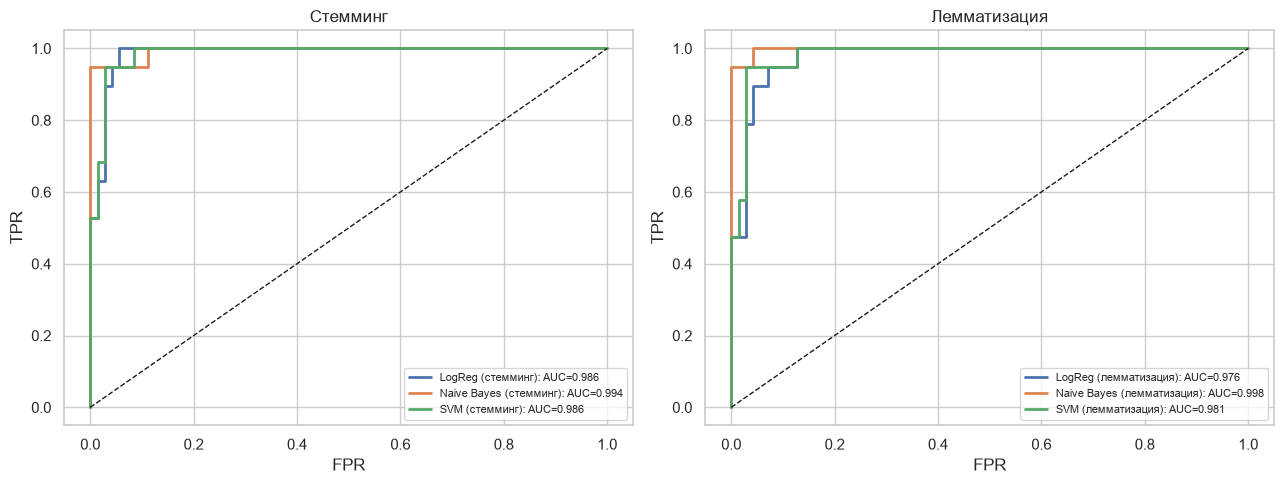

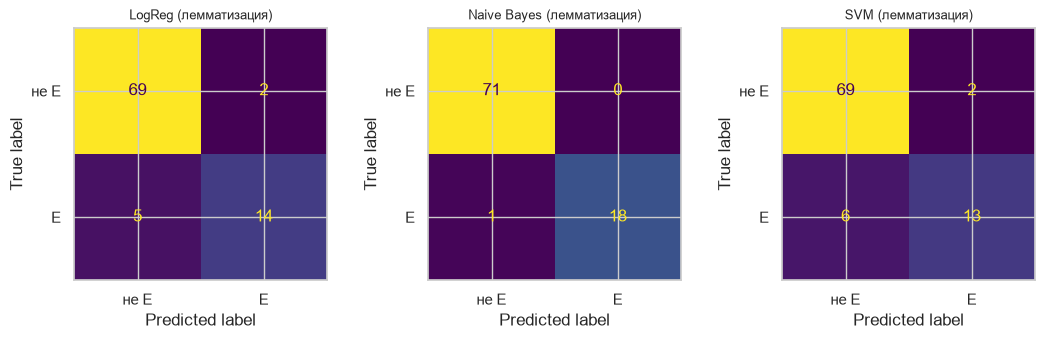

In [17]:
tuned_lemma = [k for k in out_lemma if "базовая" not in k]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
plot_roc(out_stem, tuned_stem, "Стемминг", ax[0])
plot_roc(out_lemma, tuned_lemma, "Лемматизация", ax[1])
plt.tight_layout(); plt.show()
plot_cm(out_lemma, tuned_lemma)

In [18]:
cv_lemma = cv_f1(best_lemma, "clean_lemma", "лемматизация")

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cmp = pd.concat({"стемминг": res_stem.loc[tuned_stem, metrics].rename(index=lambda s: s.split(" (")[0]),
                 "лемматизация": res_lemma.loc[tuned_lemma, metrics].rename(index=lambda s: s.split(" (")[0])}, axis=1)
cmp = cmp.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[metrics]
print("Тестовая выборка, модели после подбора параметров")
display(cmp.round(3))
print("Повторная 5-fold CV на всей выборке")
display(pd.concat([cv_stem, cv_lemma]).round(3))

Тестовая выборка, модели после подбора параметров


Accuracy              Precision                Recall  \
            стемминг лемматизация  стемминг лемматизация стемминг   
LogReg         0.933        0.922     0.882        0.875    0.789   
Naive Bayes    0.989        0.989     1.000        1.000    0.947   
SVM            0.911        0.911     0.867        0.867    0.684   

                               F1               ROC-AUC               
            лемматизация стемминг лемматизация стемминг лемматизация  
LogReg             0.737    0.833        0.800    0.986        0.976  
Naive Bayes        0.947    0.973        0.973    0.994        0.998  
SVM                0.684    0.765        0.765    0.986        0.981

Повторная 5-fold CV на всей выборке


,F1 CV mean,F1 CV std,F1 CV min
LogReg (стемминг),0.803,0.067,0.667
Naive Bayes (стемминг),0.884,0.044,0.842
SVM (стемминг),0.800,0.061,0.710
LogReg (лемматизация),0.785,0.063,0.688
Naive Bayes (лемматизация),0.888,0.049,0.833
SVM (лемматизация),0.793,0.073,0.643


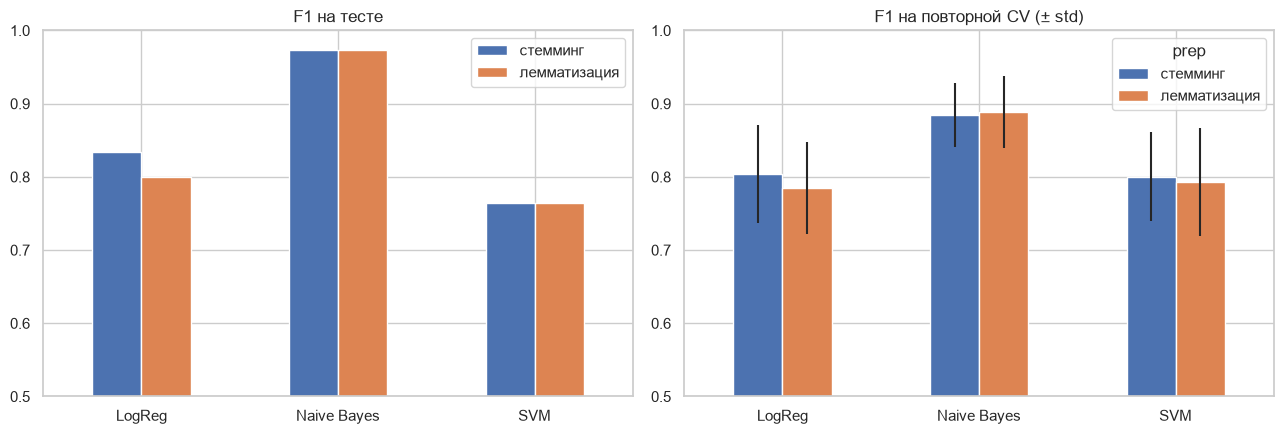

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cmp.xs("F1", axis=1, level=0).plot.bar(ax=axes[0], rot=0, color=["#4C72B0", "#DD8452"]); axes[0].set_title("F1 на тесте")
cvp = pd.concat([cv_stem, cv_lemma])
cvp["model"] = [s.split(" (")[0] for s in cvp.index]; cvp["prep"] = [s.split("(")[1][:-1] for s in cvp.index]
cvp.pivot(index="model", columns="prep", values="F1 CV mean")[["стемминг", "лемматизация"]].plot.bar(
    ax=axes[1], rot=0, color=["#4C72B0", "#DD8452"],
    yerr=cvp.pivot(index="model", columns="prep", values="F1 CV std")[["стемминг", "лемматизация"]])
axes[1].set_title("F1 на повторной CV (± std)")
for a in axes: a.set_ylim(0.5, 1); a.set_xlabel("")
plt.tight_layout(); plt.show()

### Какие слова модель считает признаками экологии

Коэффициенты логистической регрессии на лемматизированных текстах: положительный вес тянет к классу E, отрицательный – от него.

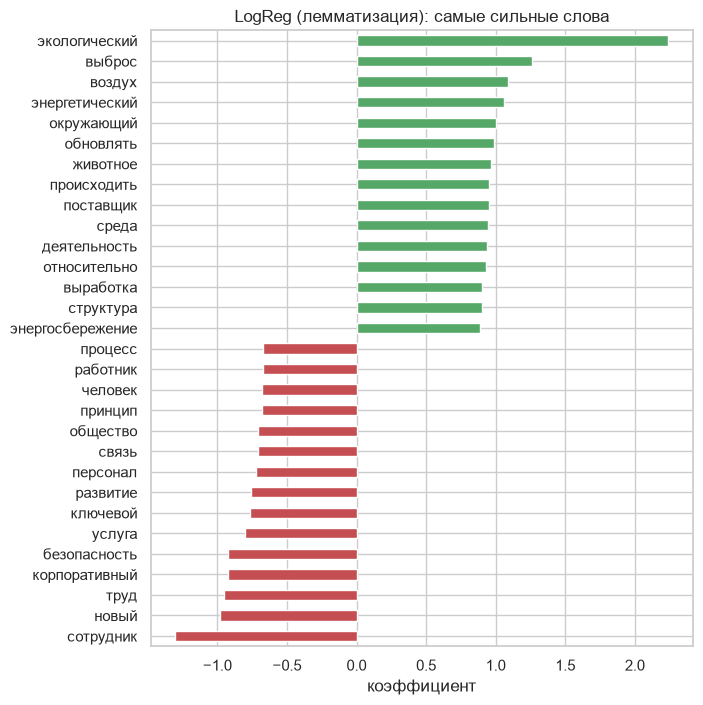

In [20]:
lr = best_lemma["LogReg"]
names = lr.named_steps["bow"].get_feature_names_out()
coef = lr.named_steps["clf"].coef_[0]
order = coef.argsort()
words = pd.concat([pd.Series(coef[order[:15]], names[order[:15]]), pd.Series(coef[order[-15:]], names[order[-15:]])])
words.plot.barh(figsize=(7, 8), color=np.where(words > 0, "#55A868", "#C44E52"))
plt.title("LogReg (лемматизация): самые сильные слова"); plt.xlabel("коэффициент")
plt.show()

In [21]:
# ошибки лучшей модели на тесте
best_key = max(tuned_lemma, key=lambda k: res_lemma.loc[k, "F1"])
pred, proba = out_lemma[best_key]
err = df.loc[idx_te].assign(pred=pred, proba=proba.round(3))
err = err[err["pred"] != err["y"]]
print(best_key, "– ошибок:", len(err))
err[["true_expert", "y", "pred", "proba", "original_text"]]

Naive Bayes (лемматизация) – ошибок: 1


,true_expert,y,pred,proba,original_text
98,Экологичность продукта,1,0,0.001,ВТБ постоянно модернизирует свою банкоматную сеть и постепенно переводит клиентов на экологические пути самообслужив...


#### Выводы по 1.5

Лемматизация почти ничего не изменила. Лемм в словаре 2957, основ 2920. Стеммер склеивает разные части речи: «эффективный», «эффективно», «эффективность» превращаются в «эффективн». Лемматизатор их разделяет, зато сводит к одной лемме формы с чередованием в корне («проведен», «проводили» → «проводить»; «разработали», «разрабатывает» → «разрабатывать»), а стеммер разносит их по разным основам. На этих текстах два эффекта примерно уравновешивают друг друга.

| Модель | F1 тест, стемминг | F1 тест, лемматизация | F1 CV, стемминг | F1 CV, лемматизация |
|---|---|---|---|---|
| Naive Bayes | 0.973 | 0.973 | 0.884 | 0.888 |
| LogReg | 0.833 | 0.800 | 0.803 | 0.785 |
| SVM | 0.765 | 0.765 | 0.800 | 0.793 |

Все разницы меньше разброса между фолдами (std 0.04–0.07), поэтому считаю стемминг и лемматизацию равными по качеству. Стемминг проще: ему не нужна внешняя программа Mystem, и работает он быстрее.

Логистическая регрессия опирается на понятные слова: «экологический», «выброс», «воздух», «энергетический», «окружающий», «среда» тянут к классу E, «сотрудник», «труд», «корпоративный», «безопасность», «персонал» – от него. Среди сильных слов есть и случайные («обновлять», «происходить», «относительно»): на 357 текстах модель запоминает слова, которые попали в пару экологических фрагментов.

Единственная ошибка Байеса на тесте – фрагмент ВТБ о банкоматах и «экологических путях самообслуживания» с темой «Экологичность продукта». Слово «экологический» там одно, остальной текст про банковское обслуживание, и модель даёт вероятность класса E 0.001. По лексике этот текст ближе к сервису, чем к экологии, и такую ошибку понять можно.

#### Выводы

1. Задачу из 45 тем свёл к бинарной: экологический блок E (96 текстов из 447, 21%) против остальных. Одна тема дала бы всего два положительных текста в тесте.
2. Лучшая модель – мультиномиальный наивный Байес на мешке слов: F1 0.973 на тесте (18 из 19 экологических текстов, ни одной ложной тревоги) и 0.88 на повторной кросс-валидации. LogReg и SVM отстают на 0.08 по F1 на кросс-валидации.
3. Из методов повышения качества сработало взвешивание классов: F1 логистической регрессии вырос с 0.727 до 0.833. Биграммы и отсечение редких слов на 357 текстах не помогают.
4. ROC-AUC у всех моделей выше 0.97. Ранжируют тексты они одинаково, а F1 различается из-за порога 0.5, который для LogReg и SVM слишком высок.
5. Лемматизация и стемминг дали одинаковое качество, разница в пределах 0.02 при разбросе 0.04–0.07.
6. В тесте 19 положительных текстов, и одна ошибка меняет Recall на 0.05. Поэтому выводы о сравнении моделей проверяю на повторной кросс-валидации, а не только на разбиении 80/20.